<a href="https://colab.research.google.com/github/Soumya454197/AI-Chatbot-/blob/main/Churn_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Core Data Science & Visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Statistical Analysis (SciPy & Statsmodels)
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Machine Learning Preprocessing & Models
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Evaluation Metrics
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix, classification_report
)

# Styling for plots
sns.set_theme(style="whitegrid")
print("Setup complete! All libraries imported successfully.")

Setup complete! All libraries imported successfully.


In [2]:
# Load the dataset into a Pandas DataFrame
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')

# Display the first 5 rows to inspect the structure
print(f"Dataset Shape: {df.shape}")
df.head()

Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# Check data types, non-null counts, and memory usage
print("--- DATASET INFO ---")
print(df.info())

# Check summary statistics for numerical columns
print("\n--- SUMMARY STATISTICS ---")
display(df.describe())

--- DATASET INFO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  704

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [4]:
# 1. Convert TotalCharges to numeric, turning empty spaces into NaN (Not a Number)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Check how many missing values were introduced
print(f"Missing values in TotalCharges: {df['TotalCharges'].isnull().sum()}")

# Fill those missing values with the median TotalCharges
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())

# 2. Drop 'customerID' because it's just a unique identifier with no predictive value for modeling
df = df.drop(columns=['customerID'])

# 3. Convert the target variable 'Churn' from Yes/No to binary (1/0)
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

print("\nData cleaning complete!")
print(f"Cleaned Dataset Shape: {df.shape}")
df.head(3)

Missing values in TotalCharges: 11

Data cleaning complete!
Cleaned Dataset Shape: (7043, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1


/tmp/ipykernel_10923/1462436587.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Churn', data=df, ax=axes[0], palette='Set2')
/tmp/ipykernel_10923/1462436587.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(['Stayed (0)', 'Churned (1)'])
/tmp/ipykernel_10923/1462436587.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Churn', y='tenure', data=df, ax=axes[1], palette='Set2')
/tmp/ipykernel_10923/1462436587.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['S

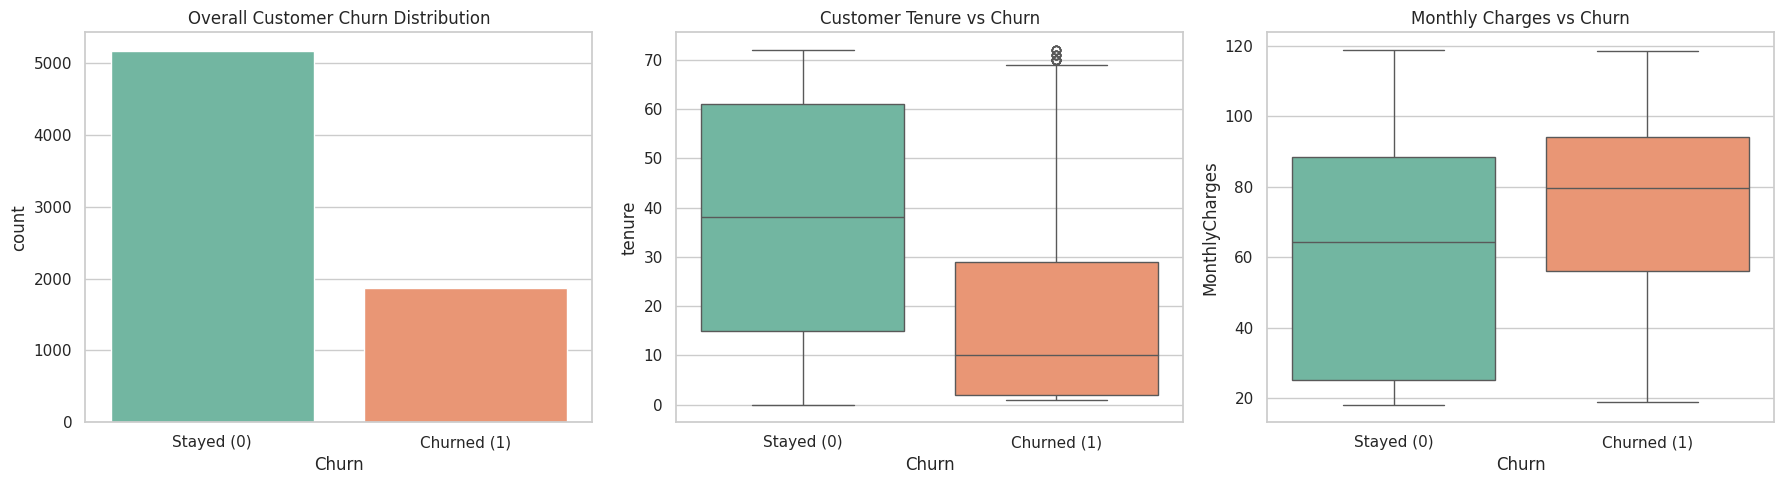

In [5]:
# Create a figure with 3 subplots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Overall Churn Rate Distribution
sns.countplot(x='Churn', data=df, ax=axes[0], palette='Set2')
axes[0].set_title('Overall Customer Churn Distribution')
axes[0].set_xticklabels(['Stayed (0)', 'Churned (1)'])

# 2. Tenure vs Churn (Boxplot)
sns.boxplot(x='Churn', y='tenure', data=df, ax=axes[1], palette='Set2')
axes[1].set_title('Customer Tenure vs Churn')
axes[1].set_xticklabels(['Stayed (0)', 'Churned (1)'])

# 3. Monthly Charges vs Churn (Boxplot)
sns.boxplot(x='Churn', y='MonthlyCharges', data=df, ax=axes[2], palette='Set2')
axes[2].set_title('Monthly Charges vs Churn')
axes[2].set_xticklabels(['Stayed (0)', 'Churned (1)'])

plt.tight_layout()
plt.show()

In [6]:
from scipy.stats import chi2_contingency

# ==========================================
# 1. CHI-SQUARE TEST: Contract Type vs Churn
# ==========================================
# Null Hypothesis (H0): Contract type has no effect on churn.
contingency_table = pd.crosstab(df['Contract'], df['Churn'])
chi2, p_val_chi, dof, expected = chi2_contingency(contingency_table)

# Calculate Cramér's V (Effect size for Chi-Square)
n = contingency_table.sum().sum()
cramers_v = np.sqrt(chi2 / (n * (min(contingency_table.shape) - 1)))

print("--- CHI-SQUARE TEST: CONTRACT vs CHURN ---")
print(f"Chi2 Statistic: {chi2:.4f}")
print(f"p-value: {p_val_chi:.4e}")
print(f"Cramér's V (Effect Size): {cramers_v:.4f}")


# ==========================================
# 2. INDEPENDENT T-TEST: Monthly Charges vs Churn
# ==========================================
# Null Hypothesis (H0): Mean monthly charges are equal for churned and stayed customers.
churned_charges = df[df['Churn'] == 1]['MonthlyCharges']
stayed_charges = df[df['Churn'] == 0]['MonthlyCharges']

t_stat, p_val_t = stats.ttest_ind(churned_charges, stayed_charges, equal_var=False)

# Calculate Cohen's d (Effect size for T-Test)
mean_diff = churned_charges.mean() - stayed_charges.mean()
pooled_std = np.sqrt(
    ((len(churned_charges) - 1) * churned_charges.var() + (len(stayed_charges) - 1) * stayed_charges.var()) /
    (len(churned_charges) + len(stayed_charges) - 2)
)
cohens_d = mean_diff / pooled_std

print("\n--- INDEPENDENT T-TEST: MONTHLY CHARGES vs CHURN ---")
print(f"t-statistic: {t_stat:.4f}")
print(f"p-value: {p_val_t:.4e}")
print(f"Cohen's d (Effect Size): {cohens_d:.4f}")

--- CHI-SQUARE TEST: CONTRACT vs CHURN ---
Chi2 Statistic: 1184.5966
p-value: 5.8630e-258
Cramér's V (Effect Size): 0.4101

--- INDEPENDENT T-TEST: MONTHLY CHARGES vs CHURN ---
t-statistic: 18.4075
p-value: 8.5924e-73
Cohen's d (Effect Size): 0.4463


In [7]:
# Select key predictor features and target for our inferential model
features_for_stats = ['tenure', 'MonthlyCharges', 'TotalCharges', 'Contract', 'PaymentMethod', 'PaperlessBilling', 'InternetService', 'Churn']
df_stats = df[features_for_stats].copy()

# Convert categorical variables into dummy/indicator variables (drop first category to avoid multicollinearity)
df_encoded = pd.get_dummies(df_stats.drop(columns=['Churn']), drop_first=True, dtype=int)

# Define X (independent variables) and y (dependent target variable)
X = sm.add_constant(df_encoded)  # Add an intercept term
y = df_stats['Churn']

# Fit the Logistic Regression model using statsmodels Logit
logit_model = sm.Logit(y, X)
result = logit_model.fit()

# Calculate Odds Ratios by exponentiating the coefficients (e^beta)
odds_ratios = np.exp(result.params)

# Combine coefficients, p-values, and odds ratios into a summary DataFrame
summary_df = pd.DataFrame({
    'Coefficient': result.params,
    'Std Error': result.bse,
    'p-value': result.pvalues,
    'Odds Ratio': odds_ratios
})

print("\n--- STATISTICAL LOGISTIC REGRESSION SUMMARY ---")
print(summary_df.to_string())

Optimization terminated successfully.
         Current function value: 0.422633
         Iterations 8

--- STATISTICAL LOGISTIC REGRESSION SUMMARY ---
                                       Coefficient  Std Error       p-value  Odds Ratio
const                                    -0.242627   0.216770  2.630210e-01    0.784564
tenure                                   -0.059007   0.006165  1.055969e-21    0.942700
MonthlyCharges                           -0.005774   0.003504  9.938494e-02    0.994242
TotalCharges                              0.000337   0.000070  1.564082e-06    1.000337
Contract_One year                        -0.763332   0.104980  3.561873e-13    0.466111
Contract_Two year                        -1.608248   0.173046  1.489274e-20    0.200238
PaymentMethod_Credit card (automatic)    -0.086016   0.112468  4.443870e-01    0.917580
PaymentMethod_Electronic check            0.410488   0.092681  9.464739e-06    1.507554
PaymentMethod_Mailed check               -0.100642   0.11

In [8]:
# Create features (X) and target (y) for machine learning
X_ml = pd.get_dummies(df.drop(columns=['Churn']), drop_first=True)
y_ml = df['Churn']

# Split data into 80% training set and 20% testing set (stratified to maintain the 26.5% churn ratio)
X_train, X_test, y_train, y_test = train_test_split(
    X_ml, y_ml, test_size=0.2, random_state=42, stratify=y_ml
)

print(f"Training Features Shape: {X_train.shape}")
print(f"Testing Features Shape: {X_test.shape}")

Training Features Shape: (5634, 30)
Testing Features Shape: (1409, 30)


In [10]:
# Initialize models (with the typo fixed)
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42)
}

evaluation_results = []

for name, model in models.items():
    # Train the model
    model.fit(X_train, y_train)

    # Make predictions
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    # Calculate performance metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc = roc_auc_score(y_test, y_prob)

    evaluation_results.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-Score": f1,
        "ROC-AUC": roc
    })

# Convert results into a clean comparison DataFrame
results_df = pd.DataFrame(evaluation_results)
print("--- MODEL EVALUATION COMPARISON ---")
display(results_df.style.format({
    "Accuracy": "{:.4f}",
    "Precision": "{:.4f}",
    "Recall": "{:.4f}",
    "F1-Score": "{:.4f}",
    "ROC-AUC": "{:.4f}"
}))

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


--- MODEL EVALUATION COMPARISON ---


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.8041,0.6541,0.5561,0.6012,0.8425
1,Decision Tree,0.7417,0.5139,0.4947,0.5041,0.6623
2,Random Forest,0.7864,0.6237,0.4920,0.5501,0.8251


/tmp/ipykernel_10923/1190241026.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feat_imp_df, palette='viridis')


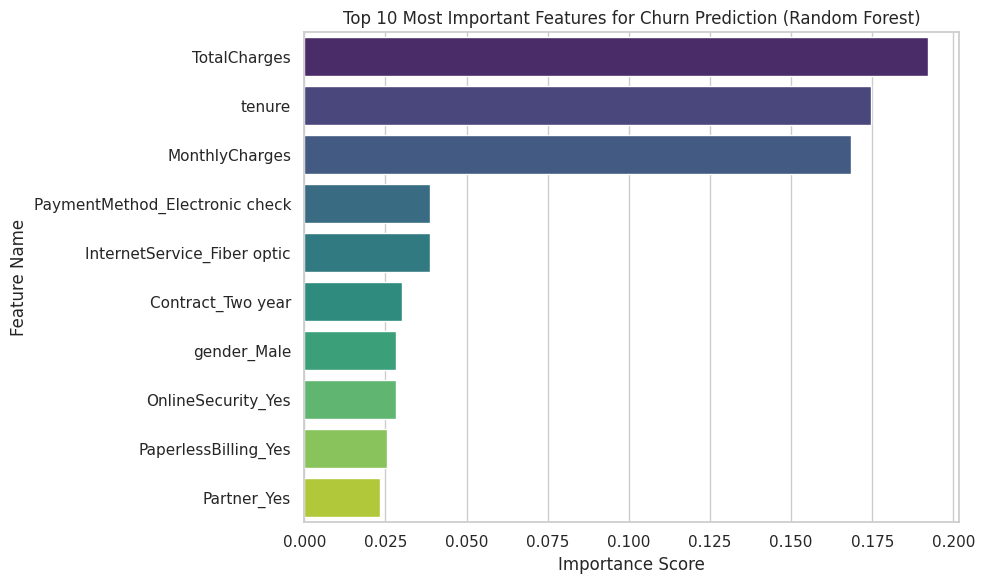

In [11]:
# Extract feature importances from the trained Random Forest model
rf_model = models["Random Forest"]
importances = rf_model.feature_importances_
feature_names = X_train.columns

# Create a DataFrame for visualization and sort top 10
feat_imp_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False).head(10)

# Plot top 10 feature importances
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feat_imp_df, palette='viridis')
plt.title('Top 10 Most Important Features for Churn Prediction (Random Forest)')
plt.xlabel('Importance Score')
plt.ylabel('Feature Name')
plt.tight_layout()
plt.show()